# Cora benchmark

{'nodes': 2708, 'directed_edge_entries': 10556, 'undirected_edges': 5278, 'features_per_node': 1433, 'mean_words_per_document': 18.17, 'classes': 7, 'class_counts': [351, 217, 418, 818, 426, 298, 180], 'mean_degree': 3.898, 'max_degree': 168, 'isolated_nodes': 0, 'edge_homophily': 0.81, 'train/val/test': [140, 500, 1000]}


,model,val_acc,test_acc,test_macro_f1,train_time_s,params
0,mlp,0.6173 ± 0.0062,0.5960 ± 0.0102,0.5746 ± 0.0096,12.00 ± 2.76,92231
1,gcn,0.8140 ± 0.0131,0.8253 ± 0.0079,0.8113 ± 0.0065,13.60 ± 3.46,23063
2,sage,0.8027 ± 0.0041,0.7987 ± 0.0041,0.7901 ± 0.0050,31.17 ± 2.98,92199
3,gat,0.8027 ± 0.0182,0.8003 ± 0.0157,0.7896 ± 0.0154,12.37 ± 2.84,23109


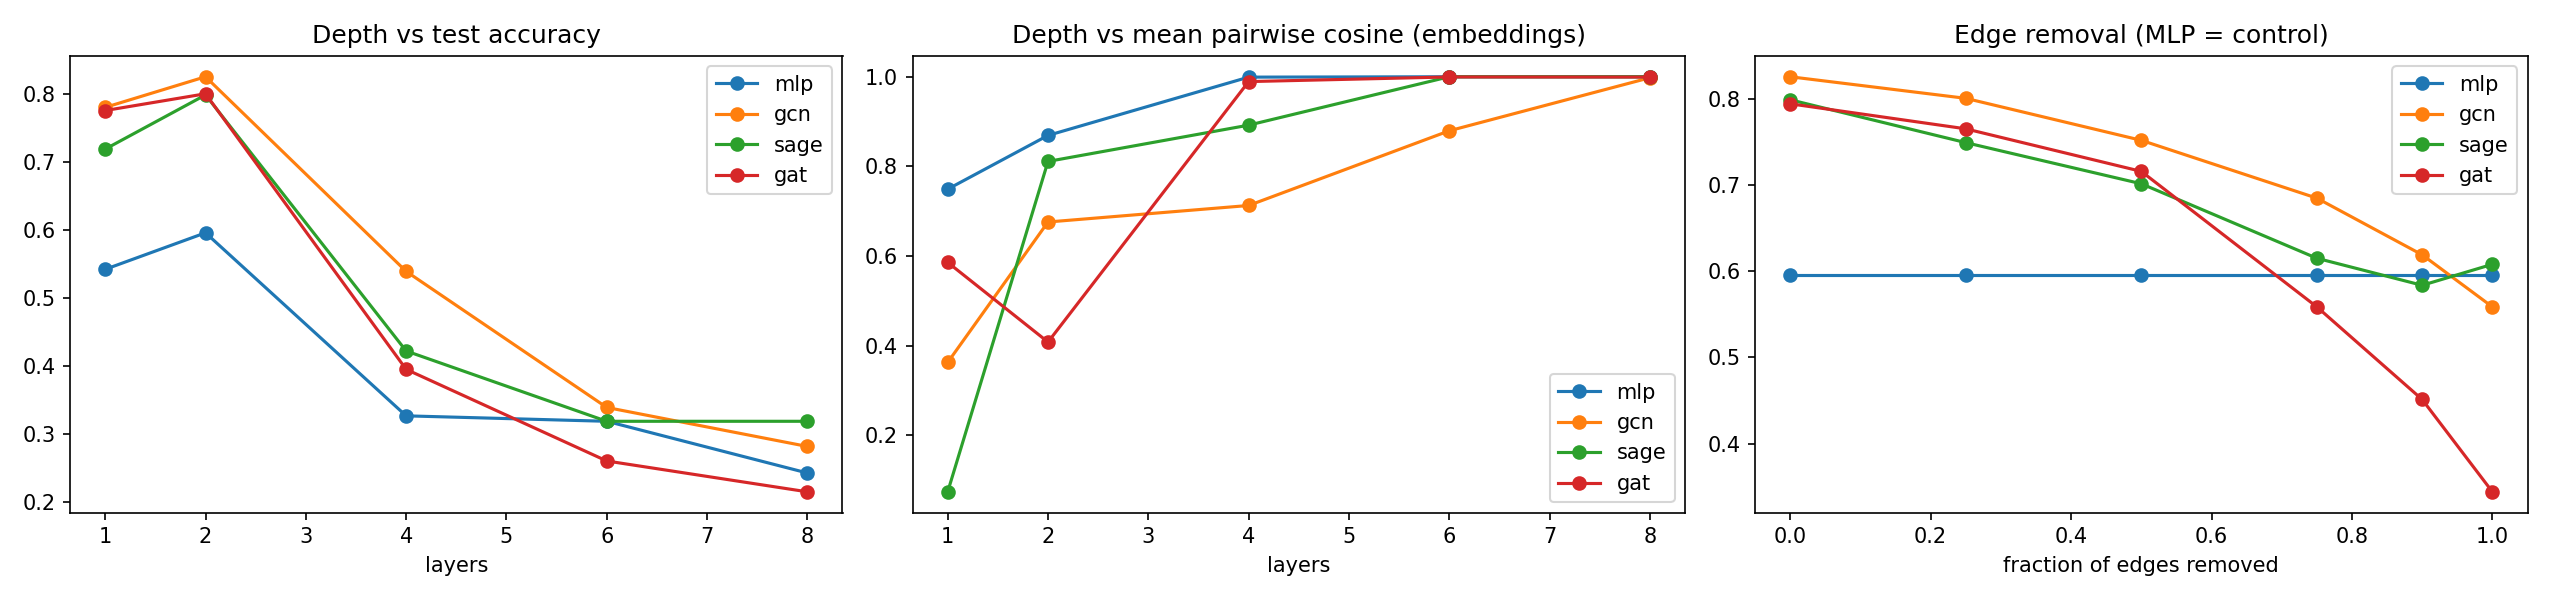

In [1]:
import pandas as pd, json, glob
from IPython.display import Image, display
R='results/cora_benchmark/'
print(json.load(open(R+'dataset_inspection.json')));display(pd.read_csv(R+'comparison.csv'));display(Image(R+'depth_and_edge_studies.png'))

In [2]:
print(open(R+'error_analysis.md').read())

# Error analysis (GCN, seed 0)

Rows: 4 most confident mistakes + 4 random mistakes.

| node | true | pred | conf | MLP pred | degree | words | neighbour true labels | neighbour predictions | nbr homophily |
|---|---|---|---|---|---|---|---|---|---|
| 2291 | 0 | 4 | 0.51 | 4 | 9 | 4 | {3: 1, 2: 1, 4: 3, 0: 4} | {4: 7, 3: 1, 0: 1} | 0.44 |
| 2484 | 3 | 4 | 0.468 | 0 | 3 | 18 | {4: 3} | {4: 3} | 0.0 |
| 1810 | 3 | 4 | 0.455 | 3 | 44 | 19 | {3: 40, 4: 1, 2: 1, 1: 2} | {3: 37, 4: 3, 1: 3, 2: 1} | 0.91 |
| 2323 | 4 | 5 | 0.42 | 5 | 2 | 5 | {5: 1, 2: 1} | {5: 2} | 0.0 |
| 2028 | 3 | 6 | 0.173 | 6 | 1 | 18 | {0: 1} | {0: 1} | 0.0 |
| 2255 | 1 | 3 | 0.178 | 3 | 1 | 20 | {1: 1} | {3: 1} | 1.0 |
| 2533 | 0 | 3 | 0.238 | 0 | 1 | 18 | {3: 1} | {3: 1} | 0.0 |
| 2356 | 0 | 4 | 0.277 | 4 | 5 | 20 | {4: 4, 0: 1} | {0: 3, 4: 2} | 0.2 |

MLP is correct on 25% of the sampled GNN errors.

Error rate by degree bucket:

             mean  count
deg_bucket              
0-1         0.253    178
2-3         0

Interpretation and recommendation: see report section 2.